# Numerical Solution to DDE
Consider the DDE

$$\begin{align}\tag{*}
y=f(&y(t),y(t-\tau),q),\,\, y(t),q\in\mathbb{R},t\ge 0,\tau>0,\\
&y(t)=\phi(t),\,\,\,t\in [-\tau,0]\\
\end{align}$$

As we concern ourselves with the bifurcation point of a DDE, it makes sense to take $\phi(t)$ as a constant i.e. $\phi(t)=y_0,\, t\in[-\tau,0]\,\,, y_0\in\mathbb{R}$ (what constant though is it going to be the bifurcation value $y^b$).
One can use the method of steps to obtain a solution for the DDE above. The method of steps is outlined below.

Consider
$$y_1'=f(y_1(t),y_1(t-\tau),q),\,\,t\in [0,\tau],$$

then $y_1(t-\tau)=\phi(t-\tau),\,\, t-\tau \in [-\tau,0]$, where $\phi(t-\tau)$ is known. Therefore, to solve for $y_1$ for $t\in [0,\tau]$ in the above equation we need to solve for the IVP

$$y_1'=f(y_1(t),\phi(t-\tau),q),\,\,t\in [0,\tau],$$

where $y_1(0)=\phi(0)$. Subsequently, we solve for 

$$y_2'=f(y_2(t),y_2(t-\tau),q),\,\,t\in [\tau,2\tau].$$

From the previous interval, $t\in[0,\tau]$, we know that $y_2(t-\tau)=y_1(t-\tau),\, t-\tau\in [0,\tau]$, therefore, we solve the IVP

$$\begin{align}
y_2'=f(&y_2(t),y_1(t-\tau),q),\,\,t\in [\tau,2\tau],\\
&y_2(\tau)=y_1(\tau).
\end{align}
$$

Likewise upon $n$ iteration of the above procedure one can arrive at the peicewise solution $y_n(t),\,\,t\in[(n-1)\tau,n\tau]$. Our DDE (*) has the solution $y_{i}(t),\, i\in\{1,\cdots,n\}$ in the respective interval $[(i-1)\tau,i\tau],\, i\in\{1,\cdots,n\}$.

To summarise the method of steps we take an initial known history function in $[-\tau,0]$, and solve the DDE as an ODE in $[0,\tau]$ with the initial value as $y_1(0)=\phi(0)$. Subsequently, we apply this procedure iteratively to peicwisely solve the DDE as an ODE in $[(i-1)\tau,i\tau],\, i\in\{2,\cdots,n\}$. The intial conditions for each of successive inteval is given by  $y_{i}((i-1)\tau)=y_{i-1}((i-1)\tau),\, i\in\{2,\cdots,n\}$, where $y_{i-1}(t),\, t\in [(i-2)\tau,(i-1)\tau]$ is already known when solving for $y_{i}(t),\, t\in [(i-1)\tau,i\tau]$.

To solve the DDE via the method of steps analytically is not always possible. Hence, we will use the trapezium method to obtain an approximate solution to equation (*).

We will employ the trapezium method to solve the DDE (*) for $t\in [0,t_{N}]$, where $t_{0}=0$ is the start time, and $t_N=T$ is the end time.

$$\begin{align}\tag{$\circ$}
y=f(&y(t),y(t-\tau),q),\,\, y(t),t\in[0,T],q\in\mathbb{R},\tau>0,\\
&y(t)=y_0,\,\,\,t\in [-\tau,0]\\
\end{align}$$

The trapezium method approximates the integral of the derivative over each time point $t_{n}$ using the trapezoidal rule [cite], thereby incorporating information from both the current and previous points. The time steps we choose to integrate over is $t_{n}=nh,\,\, n\in\{0,\cdots,N\}$, where we choose $h=\frac{\tau}{m}$ for some $m\in\mathbb{Z}^{+}$. This is done so that the delayed value, $y(t_{n}-\tau)$, in the DDE can be computed from a previous grid value without requiring interpolation. Consequently, for a chosen end time $T$ numerically we may not finish exactly at time $t_{N}=T$, as for our chosen time step $h$, the quantity $N=\frac{T}{h}$ may or may not be a positive integer. Choosing $N=\lfloor\frac{T}{h}\rfloor$ allows us to finish near $T$.

Integrating equation ($\circ$) from $t_{n}$ to $t_{n+1}$,

$$\begin{align}
\int_{t_{n}}^{t_{n+1}}y'\,dt&=\int_{t_{n}}^{t_{n+1}}f(y(t),y(t-\tau),q)\,dt\\
\implies y(t_{n+1})&=y(t_{n})+\int_{t_{n}}^{t_{n+1}}f(y(t),y(t-\tau),q)\,dt\\
\implies y(t_{n+1})&\approx y(t_{n})+\frac{t_{n+1}-t_{n}}{2}\left[f(y(t_{n}),y(t_{n}-\tau),q)+f(y(t_{n+1}),y(t_{n+1}-\tau),q)\right].
\end{align}$$

We know that $h=\frac{\tau}{m}\iff \tau=hm$, hence, $t_{n}-\tau=nh-mh=(n-m)h=t_{n-m}$. Likewise, $t_{n+1}-\tau=t_{n+1-m}$. Therefore, the above equation can be wrriten as
$$\begin{align}
y(t_{n+1})&\approx y(t_{n})+\frac{h}{2}\left[f(y(t_{n}),y(t_{n-m}),q)+f(y(t_{n+1}),y(t_{n+1-m}),q)\right].
\end{align}$$


## Special case

Given $f(y(t),y(t-\tau),q)=q+(y(t-\tau)-c_1)(y(t)-c_2)$, and $g(t_{n}):=y(t_{n}-\tau)-c_1$, $y(t_{n+1})$ can be written as 

$$\begin{equation}
y(t_{n+1})\approx y(t_n)+hq+\frac{h}{2}(y(t_{n-m})-c_1)(y(t_n)-c_2)+\frac{h}{2}(y(t_{n+1-m})-c_1)(y(t_{n+1})-c_2).
\end{equation}$$

Collecting terms with $y(t_{n+1})$:
$$\begin{align}
y(t_{n+1})-\frac{h}{2}(y(t_{n+1-m})-c_1)y(t_{n+1})&\approx y(t_n)+hq+\frac{h}{2}(y(t_{n-m})-c_1)(y(t_n)-c_2)-\frac{h}{2}(y(t_{n+1-m})-c_1)c_2\\
\implies y(t_{n+1})&\approx\frac{y(t_n)+hq+\frac{h}{2}(y(t_{n-m})-c_1)(y(t_n)-c_2)-\frac{h}{2}(y(t_{n+1-m})-c_1)c_2}{1-\frac{h}{2}(y(t_{n+1-m})-c_1)
},
\end{align}$$
where $1-\frac{h}{2}(y(t_{n+1-m})-c_1)\ne 0$ (Important condition!!). If we select $m$ to be large, as one would for better approximation,  We may now iteratively use the recurrence relation above to arrive at $y(t_{n}),\,\,t\in\{0,\cdots,N\}$.

Note whenever, $n-m<0$, we use the history function $y(t_{n-m})=\phi(t_{n-m})$ with $\phi(0)=y(0)=y_0$, else $y(t_{n-m})$ would have been obtained from a previous iteration of the procedure.

Likewise whenever, $n-m+1<0$, $y(t_{n-m+1})=\phi(t_{n-m+1})$, else $y(t_{n-m+1})$ would have been obtained from a previous iteration of the procedure.

Below we provide a pseudocode for the solving the DDE based on the method of steps and trapezoidal method outlined above.

```
Choose:
    delay τ
    parameters q, c1, c2
    history function φ(t)
    number of steps per delay m
    final time T

Set:
    h = τ/m
    t_n = nh

Initialize history:
    for n = -m,...,0:
        y_n = φ(t_n)

For n = 0,...,N-1:

    Compute delayed values:
        y_n_delay   = y_{n-m}
        y_next_delay = y_{n+1-m}

    Check:
        1 - (h/2)(y_next_delay - c1) ≠ 0

    Compute:
        y_{n+1} =
        [y_n + hq+ (h/2)(y_n_delay-c1)(y_n-c2)- (h/2)(y_next_delay-c1)c2]/[1 - (h/2)(y_next_delay-c1)]

Return:
    {t_n, y_n}
```



## Function for the solving the particular case

In [1]:
import numpy as np


def ddesolver_explicit(phi, tau, q, c1, c2, T, m):
    """
    Solve

        y'(t) = q(t) + (y(t-tau) - c1)(y(t) - c2)

    using the method of steps and the trapezium method.

    Parameters
    ----------
    phi : function
        History function on [-tau, 0].

    tau : float
        Delay.

    q : function
        Time-dependent function q(t).

    c1, c2 : float
        Parameters in the DDE.

    T : float
        Final time.

    m : int
        Number of time steps per delay.

    Returns
    -------
    t : ndarray
        Time points from -tau to T.

    y : ndarray
        Numerical solution, including the history.
    """

    # Step size
    h = tau / m

    # Number of forward time steps
    N = int(np.floor(T / h))

    # Time grid including history
    t = np.arange(-m, N + 1) * h

    # Solution array
    y = np.zeros(len(t))

    # Initialise history
    for j in range(m + 1):
        y[j] = phi(t[j])

    # Solve forward
    for j in range(m, len(t) - 1):

        # Current value
        y_n = y[j]

        # Delayed values
        y_delay_n = y[j - m]
        y_delay_next = y[j + 1 - m]

        # Denominator
        denominator = (
            1 - (h / 2) * (y_delay_next - c1)
        )

        # Check for singular denominator
        if np.isclose(denominator, 0.0):
            raise ValueError(
                f"Denominator is zero or too close to zero "
                f"at t = {t[j + 1]:.6f}"
            )

        # Trapezium update. We have q(t) instead of q. Hence, accordingly the update below.
        y[j + 1] = (
            y_n
            + (h / 2) * q(t[j])
            + (h / 2) * q(t[j + 1])
            + (h / 2)* (y_delay_n - c1)* (y_n - c2)
            - (h / 2)* (y_delay_next - c1)* c2
        ) / denominator

    return t, y

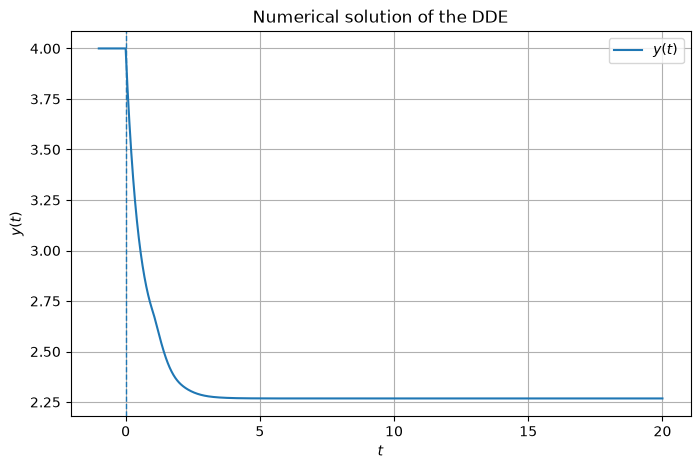

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# History function
def phi(t):
    return 4.0


# Parameters
tau = 1.0

def q(t): # This is the bifurcation value for this particular set up beyond the 4 you can see solution trajectories go unstable.
    return 1
    
c1 = 6.0 # we are choosing c1>c2
c2 = 2.0

# Take note that the bifrucation value y^b=(c_1+c_2)/2, and q^b=((c_1-c_2)/2)^2. 
# We know there's saddle node bifurcation happening so stability is expected when q<q^b and instability when q>q^b. [YES this is true :)]

# Final time
T = 20.0

# Number of time steps per delay
m = 100


# Solve the DDE
t, y = ddesolver_explicit(phi=phi,tau=tau,q=q,c1=c1,c2=c2,T=T,m=m)


# Plot the solution
plt.figure(figsize=(8, 5))

plt.plot(t, y, label=r"$y(t)$")

# Mark the history/solution transition
plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel(r"$t$")
plt.ylabel(r"$y(t)$")
plt.title("Numerical solution of the DDE")
plt.legend()
plt.grid(True)

plt.show()

## Time dependent control parameter

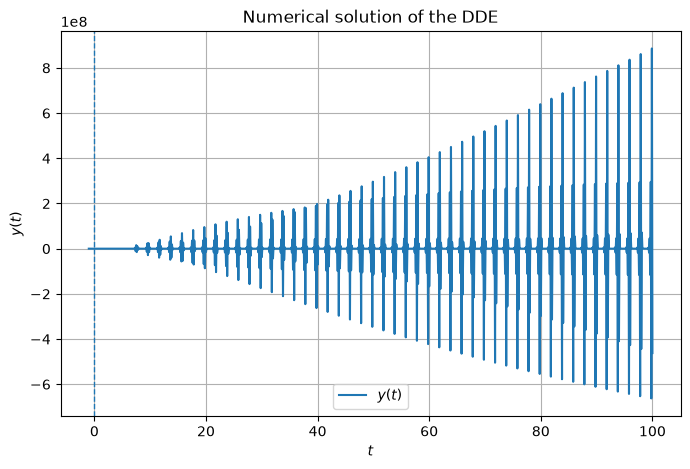

In [3]:
import numpy as np
import matplotlib.pyplot as plt

#To initialise near the q^b bifurcation value which is 4 for the chosen c_1, and c_2 values.

# History
def phi(t):
    return 4.0 


# Time-dependent q(t)
def q(t):
    q0 = 4.0
    A = 2.0
    tc = 5.0 # t=tc is the value of t where the maxima occurs. With the value of the maxima equal to q0+A.
             # The maxima is 8 for this example.
    sigma = 2.0

    return q0 + A * np.exp(
        -(t - tc)**2 / (2 * sigma**2)
    )
# Box overshoot with smooth edges 
def q1(t):
    q0 = 4.0
    A = 5.0
    t1 = 3.0
    t2 = 7.0
    sigma = 0.3

    return q0 + (A/2) * (
        np.tanh((t - t1)/sigma)
        - np.tanh((t - t2)/sigma)
    )
# Triangle overshoot 
def q2(t):
    q0 = 1.0
    A = 5.0
    tc = 5.0
    width = 4.0
    sigma = 0.2

    left = (t - (tc - width/2))
    right = ((tc + width/2) - t)

    triangle = np.maximum(
        0,
        np.minimum(left, right)
    )

    triangle = triangle / (width/2)

    return q0 + A * triangle

# Smooth assymeteric overshoot


    
# Parameters
tau = 1.0
c1 = 6.0
c2 = 2.0

T = 100
m = 10 # for small m (equivalently large step size) the ddeint breaks!

# y_reference below explodes for m=10 , and t is fixed below.
# Solve
t, y = ddesolver_explicit(
    phi=phi,tau=tau,q=q,c1=c1,c2=c2,T=T,m=m)


# Plot solution
plt.figure(figsize=(8, 5))

plt.plot(t, y, label=r"$y(t)$")

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel(r"$t$")
plt.ylabel(r"$y(t)$")
plt.title("Numerical solution of the DDE")

plt.legend()
plt.grid(True)

plt.show()


# I think they all asymptote to the same thing for different q,q1,q2 except for q3

Text(0, 0.5, '$q(t)$')

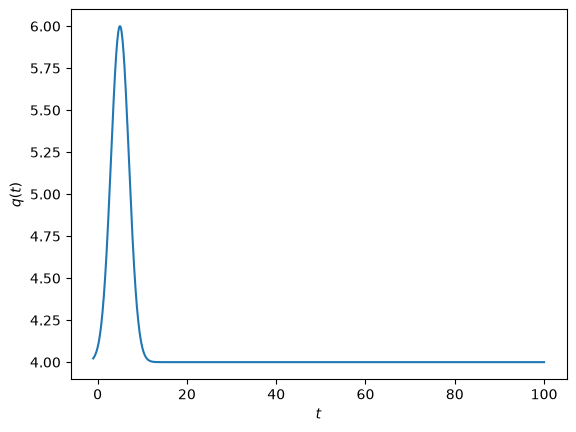

In [4]:
plt.plot(t,q(t)) # initialise the history fucntion to be the equilibrium q(0) value.
plt.xlabel(r"$t$")
plt.ylabel(r"$q(t)$")

## ddeint comparision

/opt/anaconda3/lib/python3.14/site-packages/scipy/integrate/_ode.py:420: UserWarning: vode: Repeated error test failures. (Check all input.)
  self._y, self.t = mth(self.f, self.jac or (lambda: None),
/opt/anaconda3/lib/python3.14/site-packages/scipy/integrate/_ode.py:420: UserWarning: vode: Excess work done on this call. (Perhaps wrong MF.)
  self._y, self.t = mth(self.f, self.jac or (lambda: None),
/var/folders/c7/5ncyf_1163sgs2rmcqd22q040000gn/T/ipykernel_1312/752320843.py:47: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim([0,10**6])


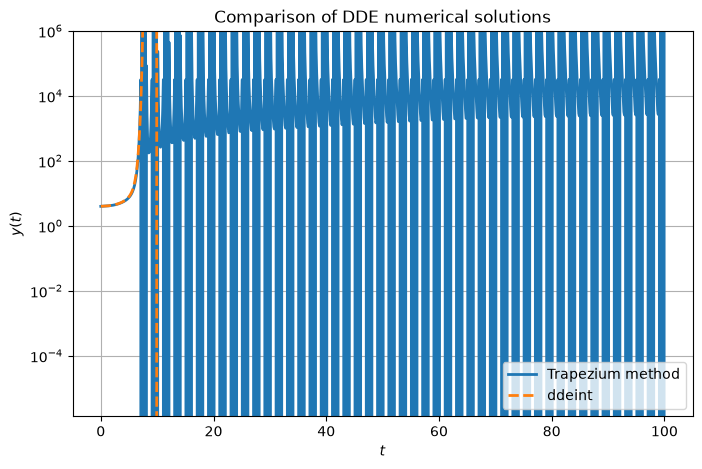

True

In [5]:
from pylab import cos, linspace, subplots
from ddeint import ddeint

# We solve the following system:
# Y(t) = phi = 1 for t < 0
# dY/dt = q+(y(t-tau)-c1)(y(t)-c2) for t > 0

def model(Y, t):
    return q(t) + (Y(t - tau) - c1) * (Y(t) - c2)

# Time points at which we want ddeint to return the solution

t_ddeint = np.linspace(0, T, len(t)-(m+1) ) # len(t)-(m+1) tells linspace that from 0 to T we only need those many elements. we have 
                                    # we have len(t)-(m+1) number of values. as we want to exclude the number of historical time values.

y_ddeint = ddeint(
    model,
    phi,
    t_ddeint
)


# Plot comparison
plt.figure(figsize=(8, 5))

# My solver
plt.plot(
    t[t >= 0],
    y[t >= 0],
    label="Trapezium method",
    linewidth=2)

# ddeint
plt.plot(
    t_ddeint,
    y_ddeint,
    "--",
    label="ddeint",
    linewidth=2)

plt.xlabel(r"$t$")
plt.ylabel(r"$y(t)$")
plt.title("Comparison of DDE numerical solutions")
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.ylim([0,10**6])
plt.show()

len(t[t>0])==len(t_ddeint)


## Error comparision ddesolver_explicit vs ddeint

The code below plots the graph of error, between ddesolver_explicit vs ddeint, as a function of the step size $h$. 

Note the error in the trapezium method due to the local truncation is $O(h^3)$, where $h$ is the step size. After approximately $T/h$ steps these local error accumulate to give a cumulative error of $O(h^2)$. Moreover, the method of steps itself does not introduce any additional errors since $h$ is chosen to be $\tau/m$, where $m$ is any, ideally, large positive integer. Therefore, the total error of the approximation scheme is $O(h^2)$.

m =   10, h = 1.000000e-01, error = 8.468398e+136
m =   20, h = 5.000000e-02, error = 1.226165e+198


/var/folders/c7/5ncyf_1163sgs2rmcqd22q040000gn/T/ipykernel_1312/752320843.py:9: RuntimeWarning: overflow encountered in scalar multiply
  return q(t) + (Y(t - tau) - c1) * (Y(t) - c2)
/opt/anaconda3/lib/python3.14/site-packages/scipy/integrate/_ode.py:420: UserWarning: vode: Repeated convergence failures. (Perhaps bad Jacobian supplied or wrong choice of MF or tolerances.)
  self._y, self.t = mth(self.f, self.jac or (lambda: None),
/opt/anaconda3/lib/python3.14/site-packages/scipy/integrate/_ode.py:420: UserWarning: vode: Illegal input detected. (See printed message.)
  self._y, self.t = mth(self.f, self.jac or (lambda: None),


m =   40, h = 2.500000e-02, error = 1.689352e+297
m =   80, h = 1.250000e-02, error = 3.481980e+303
m =  100, h = 1.000000e-02, error = 2.993997e+300
m =  200, h = 5.000000e-03, error = 5.928701e+300
m =  500, h = 2.000000e-03, error = 1.754951e+305
m = 1000, h = 1.000000e-03, error = 4.331542e+303


/opt/anaconda3/lib/python3.14/site-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


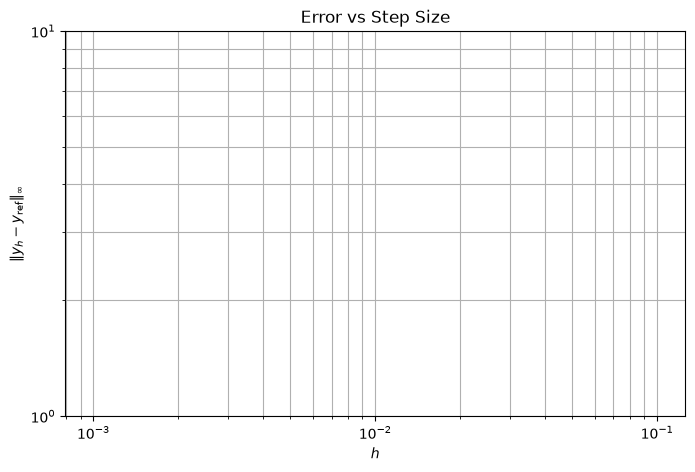

array([4.        , 3.997003  , 3.99401198, ..., 2.26794919, 2.26794919,
       2.26794919], shape=(100001,))

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from ddeint import ddeint


# Values of m


m_values = [10, 20, 40, 80, 100, 200, 500, 1000]
#m_values = [10]

h_values = []
errors = []


for m in m_values:
# Our function 
    t, y = ddesolver_explicit(
        phi=phi,
        tau=tau,
        q=q2,
        c1=c1,
        c2=c2,
        T=T,
        m=m)

    # Only compare the numerical solution for t >= 0
    index = t >= 0

    t_positive = t[index]
    y_positive = y[index]

    # Evaluate the reference solution at the same time points
    y_reference = ddeint(
        model,
        phi,
        t_positive)

    y_reference = np.asarray(y_reference).flatten() # Needed for the correct dimensions y_positive is (N,) and y_reference is (N,1)
                                                    # .flatten() reshapes the y_reference to (N,)

    # Maximum absolute error
    error = np.max(
        np.abs(y_positive - y_reference)
    )

    # Step size
    h = tau / m

    h_values.append(h)
    errors.append(error)

    print(
        f"m = {m:4d}, "
        f"h = {h:.6e}, "
        f"error = {error:.6e}"
    )



# Error vs step size


plt.figure(figsize=(8, 5))

plt.loglog(
    h_values,
    errors,
    "o-")

plt.xlabel(r"$h$")
plt.ylabel(r"$\|y_h-y_{\mathrm{ref}}\|_\infty$")
plt.title("Error vs Step Size")

plt.grid(True, which="both")

plt.show()

y_positive
# Why is a 3..... appearing for the last few values. Explore!

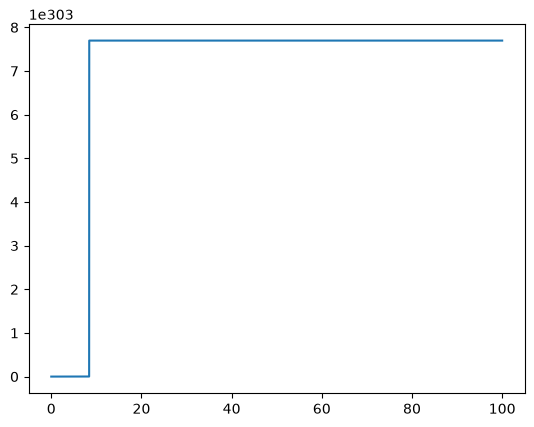

In [7]:
plt.plot(t_positive,y_reference)

(np.float64(0.0), np.float64(0.02), np.float64(0.0), np.float64(20.0))

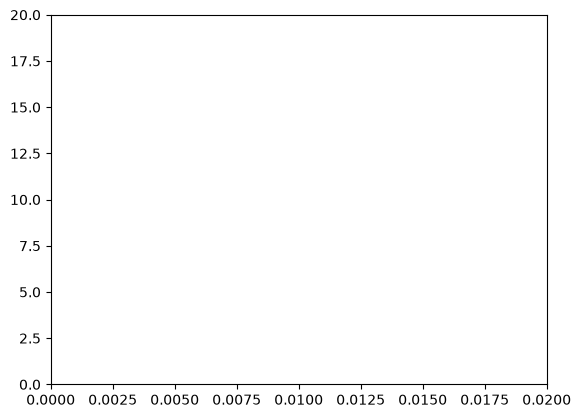

In [8]:
plt.plot(
    h_values,
    errors,
    "o-")
plt.axis([0,0.02,0,20])

In [9]:
np.min(y_positive)

np.float64(1.0)

In [10]:
np.min(y_reference)

np.float64(1.0)

## When $f$ is not explicitly given.

From the trapezoidal method and the method of steps we wish to use the following recursive relation in order to obtain a numerical approximation of $y(t)$ in $t\in\{0,\cdots,T\}$, given $y(t)=y_0$ for $t\in[-\tau,0]$
$$\begin{align}
y(t_{n+1})= y(t_{n})+\frac{h}{2}\left[f(y(t_{n}),y(t_{n-m}),q)+f(y(t_{n+1}),y(t_{n+1-m}),q)\right].
\end{align}$$

Take note that in the above $y(t_{n}),y(t_{n-m}),y(t_{n+1-m})$ are all known from previous iteration of the recurrence relation. What reamins to be found is $y(t_{n+1})$, therefore, one can use a linear taylors approximation for $f(y(t_{n+1}),y(t_{n+1-m}),q)$ about $(y_{n},y_{n+1-m},q)$ to obtain an explicit scheme.
$$\begin{align}
y(t_{n+1})= y(t_{n})+\frac{h}{2}\left[f(y(t_{n}),y(t_{n-m}),q)+f(y(t_{n}),y(t_{n+1-m}),q)+f_{y}(y(t_{n}),y(t_{n+1-m}),q)(y(t_{n+1})-y(t_{n}))\right].
\end{align}$$
Rearranging the equation above in terms of $y(t_{n+1})$ yields

$$\begin{align}
y(t_{n+1})=
\frac{y(t_n)+\dfrac{h}{2}\left[f(y(t_n),y(t_{n-m}),q)+f(y(t_n),y(t_{n+1-m}),q)\right]-\dfrac{h}{2}f_y(y(t_n),y(t_{n+1-m}),q)y(t_n)}{1-\dfrac{h}{2}f_y(y(t_n),y(t_{n+1-m}),q)}.
\end{align}$$


talk about the error term, and omission of the second order derivative terms.

In [18]:
import numpy as np


def ddesolver_explicit_1(phi, tau, f, fy, q, T, m):
    """
    Solve the DDE

        y'(t) = f(y(t), y(t-tau), q(t))

    using a method of steps with a Taylor-linearised
    explicit approximation to the trapezoidal rule.

    Parameters
    ----------
    phi : function
        History function on [-tau, 0].

    tau : float
        Delay.

    f : function
        Function f(y, y_tau, q).

    fy : function
        Partial derivative of f with respect to its first argument y:
            fy(y, y_tau, q) = df/dy.

    q : function
        q(t) 
       

    T : float
        Final time.
def phi(t):
    return 1.0


def f(y, y_tau, q):
    return y_tau * y + q


def fy(y, y_tau, q):
    return y_tau


def q(t):
    return 1.0
    m : int
        Number of steps per delay interval.

    Returns
    -------
    t : ndarray
        Time points from -tau to T.

    y : ndarray
        Numerical solution at the corresponding time points.
    """


    # Step size
    h = tau / m

    # Number of time steps
    N = int(round(T / h))

    # Time grid: history [-tau, 0] and solution [0, T]
    t = np.arange(-m, N + 1) * h

    # Solution array
    y = np.zeros(len(t))

    # Initialise history
    for j in range(m + 1):
        y[j] = phi(t[j])

    # Time stepping
    for n in range(m, len(t)-1):

        q_n = q(t[n])
        q_n1 = q(t[n + 1])

        F1 = f(
            y[n],
            y[n - m],
            q_n
        )

        F2 = f(
            y[n],
            y[n + 1 - m],
            q_n1
        )

        Fy = fy(
            y[n],
            y[n + 1 - m],
            q_n1
        )

        numerator = (
            y[n]
            + (h / 2) * (F1 + F2)
            - (h / 2) * Fy * y[n]
        )

        denominator = (
            1 - (h / 2) * Fy
        )

        y[n + 1] = numerator / denominator

    return t, y

In [23]:
def phi(t):
    return 1.0


def f(y, y_tau, q):
    return -y_tau


def fy(y, y_tau, q):
    return 0


def q(t):
    return -1.0

tau = 1.0
T = 100.0
m = 20

t, y = ddesolver_explicit_1(
    phi=phi,
    tau=tau,
    f=f,
    fy=fy,
    q=q,
    T=T,
    m=m
)

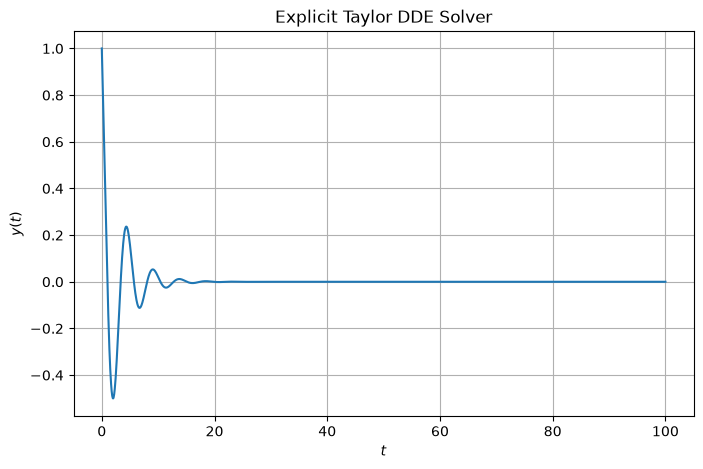

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(t[t >= 0], y[t >= 0])

plt.xlabel("$t$")
plt.ylabel("$y(t)$")
plt.title("Explicit Taylor DDE Solver")

plt.grid(True)
plt.show()

## Analytical solution vs numerical approximation comparision

Conside the DDE given below
$$\begin{equation}
y'(t)=-y(t-\tau), t\ge 0,\tau>0,
\end{equation}$$
where 
$$\begin{equation}
y(t)=1, -\tau\le t\le 0.
\end{equation}$$

One can obtain the exact analytical solution of the equation above through the method of steps. The solution of the DDE above can be written as

$$\begin{equation}
y(t)=1+\sum_{k=1}^{n}(-1)^k\frac{\left[t-(k-1)\tau\right]^k}{k!}, \,\,(n-1)\tau\le t< n\tau,n\ge 1.
\end{equation}$$

  ### Analytical solution 

In [25]:
#Explain catastrophic cancellation
# Find out why the error is so large? like why catastrophic cancellation!

import math
import numpy as np
import mpmath as mp

def y_exact(t, tau):

    mp.mp.dps = 80

    y = np.zeros(len(t))

    for i, ti in enumerate(t):

        if ti <= 0:
            y[i] = 1.0
            continue

        ti = mp.mpf(str(ti))
        tau_mp = mp.mpf(str(tau))

        n = int(mp.ceil(ti / tau_mp))

        s = mp.mpf(1)

        for k in range(1, n + 1):
            s += (
                (-1)**k
                * (ti - (k - 1)*tau_mp)**k
                / mp.factorial(k)
            )

        y[i] = float(s)

    return y

### Comparision of the analytical solution with the numerical approximation


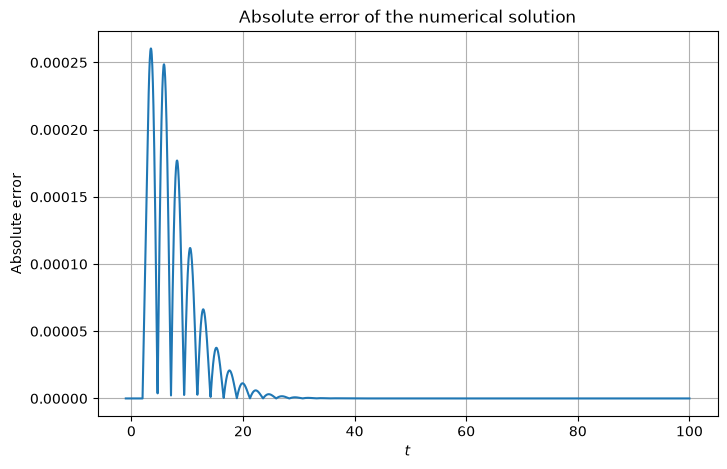

Maximum error = 0.0002604166666665131


In [22]:
# Exact solution
y_ex = y_exact(t, tau)
# Absolute error
error = np.abs(y - y_ex)#/np.abs(y_ex+0.0001) # this is the trapezium method vs the true solution comparision for the error.
                        
# Plot error
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(t, error) # The graph is inaccurate due to catastrophic cancellation.

plt.xlabel("$t$")
plt.ylabel("Absolute error")
plt.title("Absolute error of the numerical solution")

plt.grid()
plt.show()

# Maximum error
print("Maximum error =", np.max(error))

# the accumalation of the error is very noticeable for tau=pi/2. Try to see what tau values doesnt cause the weird plots for error.

In [30]:
def model(Y, t):
    return -Y(t - tau)
def phi(t):
    return 1.0



sol = ddeint(model, phi, t)

sol= np.asarray(sol).reshape(-1) 


error = np.abs(sol - y_ex) 

# Plot error
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(t, error) 

plt.xlabel("$t$")
plt.ylabel("Absolute error")
plt.title("Absolute error of the numerical solution")

plt.grid()
plt.show()

# Maximum error
print("Maximum error =", np.max(error))


ValueError: operands could not be broadcast together with shapes (101001,) (100001,) 

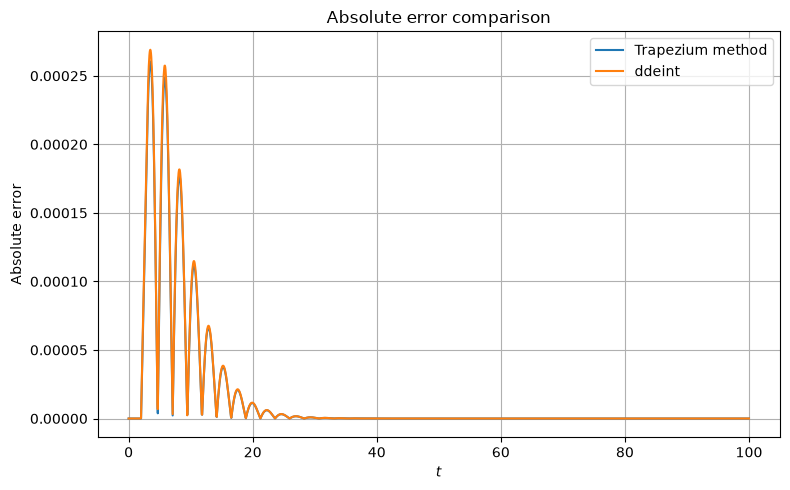

Maximum trapezium error = 0.0002604166666665131
Maximum ddeint error = 0.0002689864975646272


In [28]:

import numpy as np
import matplotlib.pyplot as plt
from ddeint import ddeint

# Use only nonnegative times
m = t >= 0
t_positive = t[m]
y_trapezium = y[m]

# Exact solution on the same time grid
y_ex = y_exact(t_positive, tau)

# Trapezium method error
error_trapezium = np.abs(y_trapezium - y_ex)

# ddeint solution, evaluated only for t >= 0
def model(Y, t):
    return -Y(t - tau)

def phi(t):
    return 1.0

sol = ddeint(model, phi, t_positive)
sol = np.asarray(sol).reshape(-1) # This reshapes the array into one dimension

# ddeint error
error_ddeint = np.abs(sol - y_ex)

# Plot both errors
plt.figure(figsize=(8, 5))
plt.plot(t_positive, error_trapezium,label="Trapezium method")
plt.plot(t_positive, error_ddeint,
         label="ddeint")

plt.xlabel("$t$")
plt.ylabel("Absolute error")
plt.title("Absolute error comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Maximum errors
print("Maximum trapezium error =",
      np.max(error_trapezium))
print("Maximum ddeint error =",
      np.max(error_ddeint))


m =  10, h = 0.100000, Trapezium error = 1.041667e-03, ddeint error = 1.046860e-03
m =  20, h = 0.050000, Trapezium error = 2.604167e-04, ddeint error = 2.689865e-04
m =  40, h = 0.025000, Trapezium error = 6.510417e-05, ddeint error = 6.754502e-05
m =  80, h = 0.012500, Trapezium error = 1.627604e-05, ddeint error = 1.685828e-05
m = 100, h = 0.010000, Trapezium error = 1.041667e-05, ddeint error = 1.107370e-05
m = 200, h = 0.005000, Trapezium error = 2.604167e-06, ddeint error = 2.679728e-06
m = 500, h = 0.002000, Trapezium error = 4.166667e-07, ddeint error = 2.038973e-06
m = 1000, h = 0.001000, Trapezium error = 1.041667e-07, ddeint error = 1.785437e-06


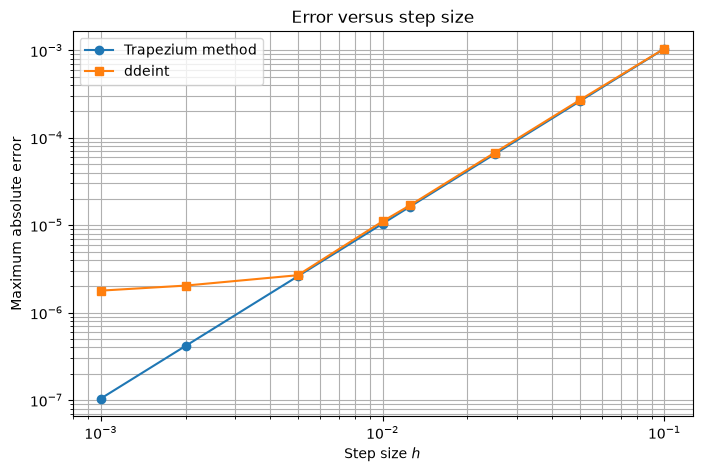

In [29]:

import numpy as np
import matplotlib.pyplot as plt
from ddeint import ddeint

# Parameters
tau = 1.0
T = 100.0

# Different numbers of steps per delay interval
m_values = [10, 20, 40, 80, 100, 200, 500, 1000]

#[5, 10, 20, 40, 80, 160,200,300,400,500]

# Store errors and step sizes
errors_trapezium = []
errors_ddeint = []
h_values = []

# Functions for the DDE: y'(t) = -y(t-tau)
def phi(t):
    return 1.0

def f(y, y_tau, q):
    return -y_tau

def fy(y, y_tau, q):
    return 0.0

def q(t):
    return -1.0

def model(Y, t):
    return -Y(t - tau)


# Calculate errors for each step size
for m in m_values:

    h = tau / m
    h_values.append(h)

    # Trapezium method
    t, y = ddesolver_explicit_1(
        phi, tau, f, fy, q, T, m
    )

    # Use only t >= 0
    t_positive = t[m:]
    y_trapezium = y[m:]

    # Exact solution at the same points
    y_ex = y_exact(t_positive, tau)

    # Trapezium error
    error_trapezium = np.max(
        np.abs(y_trapezium - y_ex)
    )
    errors_trapezium.append(error_trapezium)

    # ddeint solution on the same time grid
    sol = ddeint(model, phi, t_positive)
    sol = np.asarray(sol).reshape(-1)

    # ddeint error
    error_dde = np.max(np.abs(sol - y_ex))
    errors_ddeint.append(error_dde)

    print(
        f"m = {m:3d}, h = {h:.6f}, "
        f"Trapezium error = {error_trapezium:.6e}, "
        f"ddeint error = {error_dde:.6e}"
    )


# Plot error against step size
plt.figure(figsize=(8, 5))

plt.loglog(
    h_values, errors_trapezium, "o-",
    label="Trapezium method"
)

plt.loglog(
    h_values, errors_ddeint, "s-",
    label="ddeint"
)

plt.xlabel("Step size $h$")
plt.ylabel("Maximum absolute error")
plt.title("Error versus step size")
plt.legend()
plt.grid(True, which="both")
#plt.gca().invert_xaxis()
#plt.tight_layout()
plt.show()
# unpack the error and make sure the error above lrelfelcts the things

## DDE-IVP Package


In [23]:
pip install dde-ivp

Note: you may need to restart the kernel to use updated packages.


my dde solver


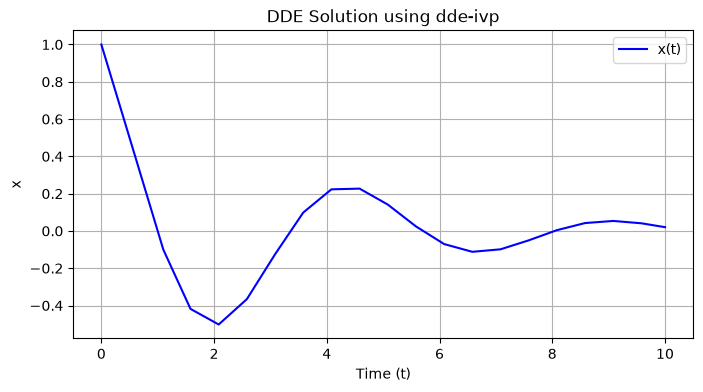

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from dde_ivp import solve_ddeivp

# 1. Define the system of equations
# Y is the history function/interpolator function provided by the solver.
def model(t, Y):
    # Retrieve the state at the delayed time (t - 1.0)
    delayed_x = Y(t - 1.0) 
    
    # Differential equation: dx/dt = -x(t - 1)
    dxdt = -delayed_x[0] # Slice the array returned by Y
    return [dxdt]

# 2. Define the history function for t <= 0 (must return an array/list)
def history(t):
    return [1.0]

# 3. Define configuration
t_span = (0.0, 10.0)
y0 = [1.0]      # Initial state vector at t = 0
max_step = 0.5  # Max step size should not exceed the minimum delay (1.0)

# Solve the DDE IVP
sol = solve_ddeivp(
    model,
    t_span,
    history,  
    method='RK45',
    max_step=max_step
)

# 5. Plot the results
plt.figure(figsize=(8, 4))
plt.plot(sol.t, sol.y[0], label='x(t)', color='blue') # sol.y is a 2D array
plt.title("DDE Solution using dde-ivp")
plt.xlabel("Time (t)")
plt.ylabel("x")
plt.grid(True)
plt.legend()
plt.show()


## Saltzman and Maasch Model
The Delay model approximation for SM88 is given by 
\begin{equation}
    \frac{d{x}}{d{t}}=rx(t)-qx(t-\tau)-x(t-\tau)^2[s+x(t)],
\end{equation}
where $x(t)$ is the ice mass anomaly. 

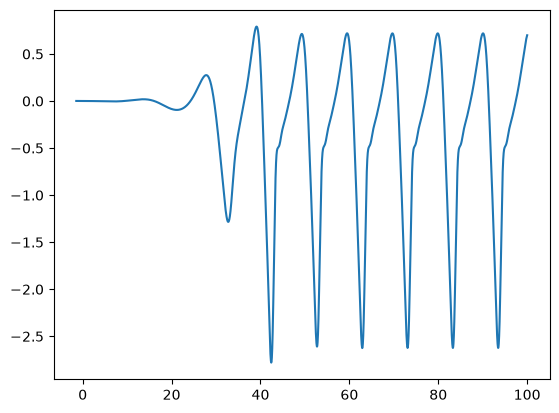

In [23]:
def phi(t):
    return 0.001

def q(t):
    return 1

r=0.8 # Just keep these values for r, and s throughout for now!
s=0.8    
def f(y,y_tau,q):
    return r*y-q*y_tau-(y_tau**2)*(s+y)
def fy(y,y_tau,q):
    return r-y_tau**2
tau=1.45
T=100
m=100

t,x=ddesolver_explicit_1(phi, tau, f, fy, q, T, m)

plt.plot(t,x)